[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vzavala/PIML_PEQ_2026/blob/main/JupyterNotebooks/PEQ_Colloquium_Tutorial_2.ipynb)

# Tutorial 2: Neural ODEs and Variational Inference for Microkinetic Modeling
## Physics-Constrained Machine Learning: Concepts, Tools, and Algorithms

**Victor M. Zavala and Angan Mukherjee — University of Wisconsin-Madison**

This hands-on tutorial is given at the **end of the workshop** to reinforce the concepts of Modules 1-3 with a dynamic
microkinetic model of CO oxidation. In Tutorial 1, we first estimated model parameters and then quantified uncertainty
by bootstrap refitting. **Variational inference (VI) instead estimates the parameters and their uncertainty
simultaneously by solving an optimization problem.** In this tutorial, we will:

1. Simulate a CO oxidation microkinetic model and see how prior parameter uncertainty becomes predictive uncertainty.
2. Train a neural ODE (repeated simulation) and an ensemble of 50 neural ODEs.
3. Estimate the rate constants and their uncertainty with VI, solved with Adam.
4. Propagate the VI posterior through the dynamic model and compare all models.

### Connection to the slides (Modules 1-3)

The equations below use the notation of the slides. Where the code uses a different name, it is given in parentheses.

| Concept | Notation (code name) | Slides |
|---|---|---|
| Neural ODE | $d\widehat x/dt=\mathrm{ML}_\theta(\widehat x)$, $p=148$ params | Neural ODE, trained by repeated simulation (Module 1) |
| Microkinetic ODE with unknown rate constants | Physics model with known structure | Physics-based model (Module 2) |
| Ensemble of 50 NODEs | Spread due to initialization | Not a Bayesian posterior (Module 3) |
| Log-rate parameters | $\theta=\log k$ (`u`), prior $\mathcal{N}(\bar\theta,\Sigma_\theta)$ (`prior_mu`, `prior_sd`) | Parameters $\theta$ with Gaussian prior (Module 3) |
| Variational density | $q(\theta\mid\lambda)$, $\lambda=(\mu,\rho)$ (`phi`), $\sigma=e^{\rho}$ | Mean-field VI, maximize ELBO (Module 3) |
| Monte Carlo samples | $\theta_s=\mu+\sigma\odot\varepsilon_s$, $s=1,\dots,N_s$ (`MC_SAMPLES`) | Reparameterization trick (Module 3) |
| Optimizer | Adam on $-\mathrm{ELBO}(\lambda)$ | Gradient-based solution of VI (Module 3) |

Densities are written $f(\cdot)$ as in the slides: likelihood $f(\mathbf{y}\mid\theta)$, prior $f(\theta)$, posterior $f(\theta\mid\mathbf{y})$.

### Before the workshop

    conda create -n pcml -c conda-forge python=3.11 numpy scipy matplotlib jupyterlab ipykernel
    conda activate pcml
    python -m pip install "jax[cpu]"
    jupyter lab

JAX provides automatic differentiation and compiled ODE calculations.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.stats import lognorm
import jax
import jax.numpy as jnp
from jax import jit, vmap, lax, tree_util

jax.config.update("jax_enable_x64", True)
SEED = 26
rng = np.random.default_rng(SEED)
plt.rcParams.update({
    "text.usetex": False, # Set to True if you have an external LaTeX installation
    "font.family": "serif",
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11
})
labels = [r"$\phi_{CO}$", r"$\phi_O$", r"$\phi_{CO_2}$", r"$\phi_S$"]
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

### 1. CO oxidation: kinetic model
We use a four-state model of CO oxidation on a catalytic surface. Write
$x=(\phi_{CO},\phi_O,\phi_{CO_2},\phi_S)$ for the surface coverages of adsorbed CO, O, CO2, and vacant sites.

The simplified reaction mechanism is
$$CO(g)+S\to CO^*,\qquad O_2(g)+2S\to2O^*,$$
$$CO^*+O^*\to CO_2^*+S,\qquad CO_2^*\to CO_2(g)+S$$
Define
$$r_1=k_1\phi_S,\quad r_2=k_2\phi_S^2,\quad
r_3=k_3\phi_{CO}\phi_O,\quad r_4=k_4\phi_{CO_2}$$
Fixed gas-phase conditions are incorporated into the effective adsorption parameters $k_1$ and $k_2$.

The governing equations are
$$\frac{d\phi_{CO}}{dt}=r_1-r_3$$
$$\frac{d\phi_O}{dt}=2r_2-r_3$$
$$\frac{d\phi_{CO_2}}{dt}=r_3-r_4$$
$$\frac{d\phi_S}{dt}=-r_1-2r_2+r_3+r_4$$

Use an initially clean surface and the following (true) rate constants:
$$x_0=(0,0,0,1),\qquad k=(0.5,0.2,0.6,0.7)$$
The time interval is 0–10 min, and the same synthetic observations are used by every method.

The equations satisfy $\mathbf{1}^T\dot x=0$, preserving
$$\phi_{CO}+\phi_O+\phi_{CO_2}+\phi_S=1$$
This balance is built into the physical ODE for every parameter sample; no additional constraint or physics penalty is needed in VI-PCML.


In [2]:
x0 = np.array([0.0, 0.0, 0.0, 1.0])
k_true = np.array([0.5, 0.2, 0.6, 0.7])
sigma_y = 0.02
T_TRAIN, T_END, DT = 10.0, 10.0, 0.05
# Integration grids; measurements are taken every 0.2 min.
t_train = np.linspace(0, T_TRAIN, int(round(T_TRAIN/DT))+1)
t_plot = np.linspace(0, T_END, int(round(T_END/DT))+1)
obs_idx = np.arange(4, len(t_train), 4)  
t_obs = t_train[obs_idx]

# Rows: CO, O, CO2, S. Columns: reaction steps 1–4
C = np.array([[1, 0, -1, 0], [0, 2, -1, 0],
              [0, 0, 1, -1], [-1, -2, 1, 1]], dtype=float)

def rhs_numpy(t, x, k):
    co, o, co2, s = x
    rates = np.array([k[0]*s, k[1]*s*s, k[2]*co*o, k[3]*co2])
    return C @ rates

def simulate_numpy(k, times=t_plot):
    sol = solve_ivp(rhs_numpy, (0, float(times[-1])), x0,
                    t_eval=times, args=(k,), rtol=1e-9, atol=1e-11)
    if not sol.success or not np.isfinite(sol.y).all():
        raise RuntimeError(sol.message)
    return sol.y.T

y_true = simulate_numpy(k_true)
y_obs_true = simulate_numpy(k_true, t_obs)
y_obs = y_obs_true + sigma_y*rng.normal(size=y_obs_true.shape)

def four_species_plot(mean, title, lower=None, upper=None, data=True):
    fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
    for j, ax in enumerate(axes.flat):
        ax.plot(t_plot, y_true[:, j], "k--", label="Synthetic truth")
        ax.plot(t_plot, mean[:, j], color=colors[j], label="Model mean")
        if lower is not None:
            ax.fill_between(t_plot, lower[:, j], upper[:, j],
                            color=colors[j], alpha=0.25, label="Pointwise band")
        if data:
            ax.scatter(t_obs, y_obs[:, j], color=colors[j], s=14,
                       alpha=0.65, label="Measurements")
        ax.set(title=labels[j], xlabel="Time (min)", ylabel="Coverage")
        ax.grid(alpha=0.35)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

### 2. How parameter uncertainty becomes predictive uncertainty
Before fitting any data, suppose the positive kinetic constants are uncertain. Introduce dimensionless log-rate variables
$$\theta_j=\log(k_j/k_{ref}),\quad k_{ref}=1\ \mathrm{min}^{-1},\qquad
\theta\sim\mathcal N(\bar\theta,\Sigma_\theta),\quad \Sigma_\theta=\mathrm{diag}(\tau_j^2)$$
Numerically, $k_j=\exp(\theta_j)$ when rates are expressed in min$^{-1}$. Use prior median 0.5 min$^{-1}$ and log-standard deviation 0.6 for each rate. These are illustrative assumptions chosen independently of the synthetic truth, not estimated from it.

Draw $\theta_s$, $s=1,\dots,N_s$, from the prior, transform to $k_s=\exp(\theta_s)$, and solve the physical ODE for each sample. Different parameter draws give different trajectories. The resulting **prior response bands** describe parameter-induced uncertainty before seeing measurements; they do not include instrument noise.

After observing data, VI will learn a distribution that balances data fit with the prior. We will propagate that learned distribution in exactly the same way.

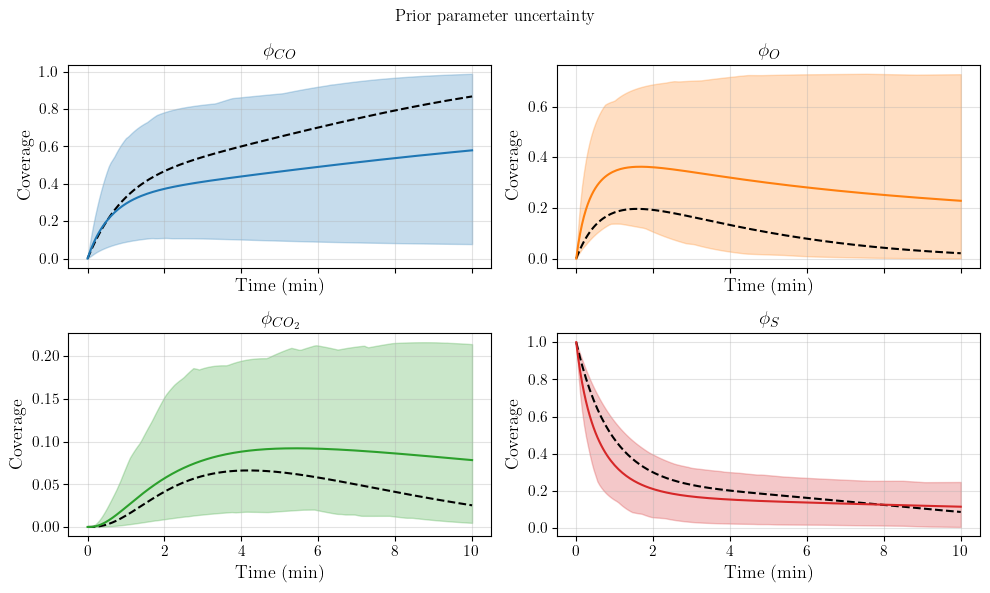

In [3]:
prior_mu = np.full(4, np.log(0.5))
prior_sd = np.full(4, 0.6)
rng_prior = np.random.default_rng(SEED+1)
k_prior = np.exp(prior_mu + prior_sd*rng_prior.normal(size=(200, 4)))
prior_paths = np.stack([simulate_numpy(k) for k in k_prior])
prior_lo, prior_hi = np.quantile(prior_paths, [0.025, 0.975], axis=0)
four_species_plot(prior_paths.mean(0), "Prior parameter uncertainty",
                  prior_lo, prior_hi, data=False)

### 3. Neural ODE: learn the vector field
A NODE replaces the known kinetic vector field by a neural function:
$$\frac{d\widehat x}{dt}=\mathrm{ML}_\theta(\widehat x),\qquad \widehat x(0)=x_0$$
Here $\mathrm{ML}_\theta(x)=W_2\tanh(W_1x+b_1)+b_2$, with four inputs, 16 hidden units, and four derivative outputs ($p=148$ parameters). This is a continuous-time model: the NN predicts a derivative, and an ODE solver produces the trajectory.

Train by minimizing
$$L(\theta)=\frac{1}{4N}\sum_{\omega\in\mathcal S}\sum_{j=1}^{4}
\left(\frac{\widehat x_j(t_\omega;\theta)-y_{\omega j}}{\sigma_y}\right)^2$$
where $y_{\omega j}$ is the measured coverage $j$ at time $t_\omega$, $\omega\in\mathcal S$, and $N=|\mathcal S|$.

For a transparent implementation, use fixed-step fourth-order Runge–Kutta (RK4) and differentiate through its operations with JAX. This is direct differentiation through the discretized ODE, not an adjoint implementation. 

Iteration 400: mean loss = 1.8025
Iteration 800: mean loss = 1.1845
Iteration 1200: mean loss = 1.1193
Trained 1 model(s) in 1.6 s


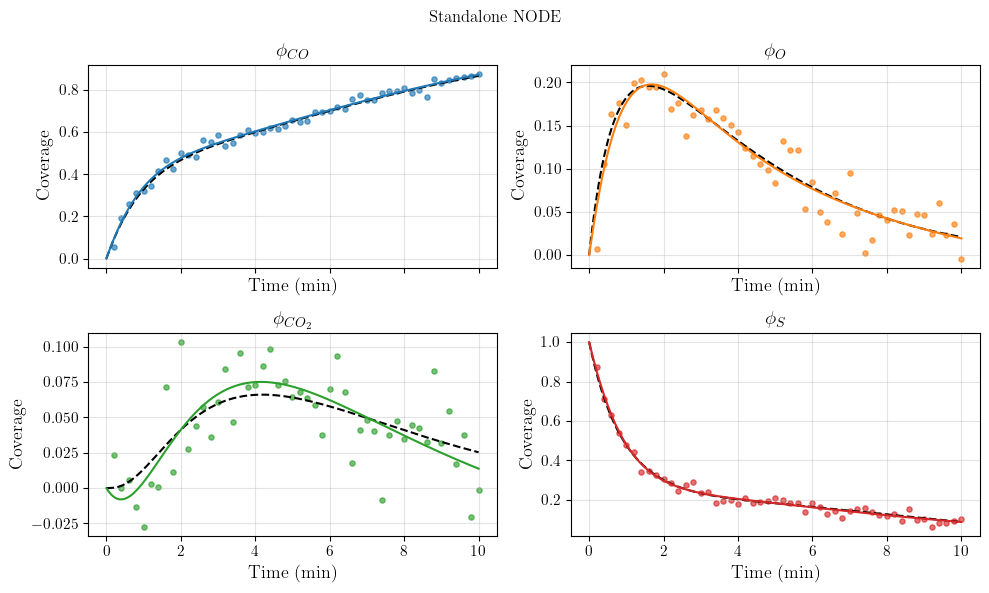

In [4]:
x0_j = jnp.array(x0)
t_train_j, t_plot_j = jnp.array(t_train), jnp.array(t_plot)
obs_idx_j, y_obs_j = jnp.array(obs_idx), jnp.array(y_obs)
C_j = jnp.array(C)

def rk4(rhs, x_initial, times, params):
    def step(x, dt):
        a = rhs(x, params)
        b = rhs(x + dt*a/2, params)
        c = rhs(x + dt*b/2, params)
        d = rhs(x + dt*c, params)
        x_next = x + dt*(a + 2*b + 2*c + d)/6
        return x_next, x_next
    _, path = lax.scan(step, x_initial, jnp.diff(times))
    return jnp.concatenate([x_initial[None, :], path], axis=0)

def kinetic_rhs(x, k):
    co, o, co2, s = x
    return C_j @ jnp.array([k[0]*s, k[1]*s*s, k[2]*co*o, k[3]*co2])

def init_node(key):
    key1, key2 = jax.random.split(key)
    return {"W1": jax.random.normal(key1, (16, 4))/2,
            "b1": jnp.zeros(16),
            "W2": 0.1*jax.random.normal(key2, (4, 16))/4,
            "b2": jnp.zeros(4)}

def node_rhs(x, w):
    return w["W2"] @ jnp.tanh(w["W1"] @ x + w["b1"]) + w["b2"]

def node_loss(w):
    pred = rk4(node_rhs, x0_j, t_train_j, w)[obs_idx_j]
    return jnp.mean(((pred-y_obs_j)/sigma_y)**2)

# Adam works with either a dictionary of NN weights or VI parameters
def adam_init(params):
    zeros = tree_util.tree_map(jnp.zeros_like, params)
    return zeros, zeros

@jit
def adam_update(params, grad, m, v, iteration, lr):
    b1, b2 = 0.9, 0.999
    m = tree_util.tree_map(lambda a, g: b1*a+(1-b1)*g, m, grad)
    v = tree_util.tree_map(lambda a, g: b2*a+(1-b2)*g*g, v, grad)
    params = tree_util.tree_map(
        lambda p, a, b: p-lr*(a/(1-b1**iteration)) /
        (jnp.sqrt(b/(1-b2**iteration))+1e-8), params, m, v)
    return params, m, v

node_value_grad = jit(vmap(jax.value_and_grad(node_loss)))
node_predict_many = jit(vmap(lambda w: rk4(node_rhs, x0_j, t_plot_j, w)))

def train_nodes(seeds, epochs=1200, lr=0.003):
    # Leading array dimension indexes independent models, not shared weights.
    keys = jnp.stack([jax.random.PRNGKey(s) for s in seeds])
    params = vmap(init_node)(keys)
    m, v = adam_init(params)
    started = time.perf_counter()
    for it in range(1, epochs+1):
        values, grad = node_value_grad(params)
        if not np.isfinite(np.asarray(values)).all():
            raise RuntimeError("Nonfinite NODE loss; reduce the learning rate.")
        params, m, v = adam_update(params, grad, m, v, it, lr)
        if it % 400 == 0:
            print(f"Iteration {it}: mean loss = {float(values.mean()):.4f}")
    final_losses = np.asarray(vmap(node_loss)(params))
    predictions = np.asarray(node_predict_many(params))
    if not np.isfinite(predictions).all():
        raise RuntimeError("Nonfinite NODE predictions")
    print(f"Trained {len(seeds)} model(s) in {time.perf_counter()-started:.1f} s")
    return params, predictions, final_losses

single_params, single_paths, single_loss = train_nodes([100])
single_pred = single_paths[0]
four_species_plot(single_pred, "Standalone NODE")

### 4. Ensemble of 50 randomly initialized NODEs
Train 50 models with different initial weights, using the **same data, architecture, optimizer, and number of iterations** as the standalone NODE. The code vectorizes their independent calculations for speed; it does not couple their parameters or average gradients across models.

The ensemble mean summarizes their predictions. The displayed 2.5–97.5 percentile envelope summarizes **initialization-dependent model spread**. 

The standalone model has a separate seed and is not counted among the 50 ensemble members.

Iteration 400: mean loss = 2.1813
Iteration 800: mean loss = 1.3691
Iteration 1200: mean loss = 1.1920
Trained 50 model(s) in 19.4 s


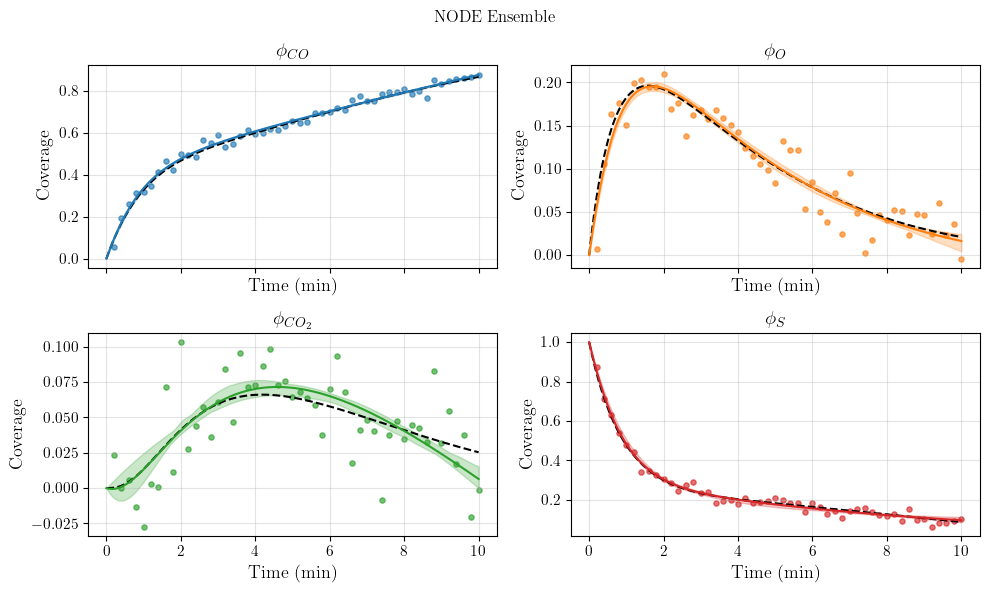

In [5]:
ensemble_params, ensemble_paths, ensemble_losses = train_nodes(list(range(50)))
ensemble_mean = ensemble_paths.mean(axis=0)
ensemble_lo, ensemble_hi = np.quantile(ensemble_paths, [0.025, 0.975], axis=0)
four_species_plot(ensemble_mean, "NODE Ensemble",
                  ensemble_lo, ensemble_hi)

### 5. Variational inference: fit a parameter distribution
Let $\mathbf{y}=\{y_\omega\}_{\omega\in\mathcal S}$ contain the four noisy coverages observed at times $t_\omega>0$. The initial state is known and is not included as a noisy observation. Let $\widehat x(t_\omega;\theta)$ be the solution of the **microkinetic ODE** with $k=\exp(\theta)$, not the NODE.

Assume independent Gaussian measurement errors:
$$f(\mathbf{y}\mid\theta)=\prod_{\omega\in\mathcal S}\prod_{j=1}^{4}
\mathcal N\left(y_{\omega j};\widehat x_j(t_\omega;\theta),\sigma_y^2\right)$$
The likelihood uses independent measurement errors for all four observed variables.

Bayes' theorem gives
$$f(\theta\mid\mathbf{y})=\frac{f(\mathbf{y}\mid\theta)f(\theta)}{f(\mathbf{y})},\qquad
f(\mathbf{y})=\int f(\mathbf{y}\mid\theta)f(\theta)\,d\theta$$
The evidence integral is generally difficult to evaluate. VI chooses a tractable distribution
$$q(\theta\mid\lambda)=\prod_{j=1}^{4}\mathcal N(\theta_j\mid\mu_j,\sigma_j^2),\qquad
\lambda=(\mu,\rho),\qquad \sigma_j=e^{\rho_j}$$
and minimizes the **reverse KL divergence**:
$$\mathrm{KL}\left(q(\theta\mid\lambda)\,\Vert\, f(\theta\mid\mathbf{y})\right)
=\mathbb E_q\left[\log q(\theta\mid\lambda)-\log f(\theta\mid\mathbf{y})\right]$$
Substitute Bayes' theorem and collect terms:
$$\mathrm{KL}\left(q\,\Vert\, f(\theta\mid\mathbf{y})\right)=\mathbb E_q[\log q(\theta\mid\lambda)-\log f(\theta)-\log f(\mathbf{y}\mid\theta)]
+\log f(\mathbf{y})$$
The last term does not depend on $\lambda$. Therefore minimizing KL is equivalent to maximizing the **evidence lower bound** (ELBO):
$$\max_\lambda\;\mathrm{ELBO}(\lambda)=\mathbb E_q[\log f(\mathbf{y}\mid\theta)]
-\mathrm{KL}\left(q(\theta\mid\lambda)\,\Vert\, f(\theta)\right)$$
The code minimizes the negative ELBO, $-\mathrm{ELBO}(\lambda)$, which is equivalent.
The likelihood term rewards agreement with the data; the KL-to-prior term penalizes departures from the prior and includes the entropy contribution that prevents fitting only a point estimate.

For our diagonal Gaussian prior and variational distribution, this KL is analytic:
$$\mathrm{KL}\left(q(\theta\mid\lambda)\,\Vert\, f(\theta)\right)=\frac12\sum_{j=1}^{4}
\left[\frac{\sigma_j^2+(\mu_j-\bar\theta_j)^2}{\tau_j^2}-1
+2\log\frac{\tau_j}{\sigma_j}\right]$$

**Reparameterization:** draw $\varepsilon_s\sim\mathcal N(0,I)$ and set
$$\theta_s=\mu+\sigma\odot\varepsilon_s,\qquad k_s=\exp(\theta_s),\qquad s=1,\dots,N_s$$
This allows differentiation through the sample transformation and ODE solver. In log space, $|\det(\partial \theta_s/\partial\varepsilon_s)|=\prod_j \sigma_j$, which yields the Gaussian entropy term. The prior and approximate posterior are both defined in log space, so no extra $k$-space Jacobian term is needed in this objective. The corresponding distributions of positive $k_j$ are lognormal.

Using $N_s$ **fresh samples at every update** (`MC_SAMPLES` in code), and dropping likelihood constants independent of $\lambda$:
$$-\mathrm{ELBO}(\lambda)\approx\frac{1}{N_s}\sum_{s=1}^{N_s}
\frac12\sum_{\omega,j}\left(\frac{y_{\omega j}-\widehat x_j(t_\omega;\theta_s)}{\sigma_y}\right)^2
+\mathrm{KL}\left(q(\theta\mid\lambda)\,\Vert\, f(\theta)\right)$$
All observations are used at each update; stochasticity comes from resampling $\varepsilon_s$. Both $\mu$ and $\rho$ are optimized together.

### 6. Adam: adaptive moment estimation
Ordinary stochastic gradient descent updates $\lambda_{\ell+1}=\lambda_\ell-\eta g_\ell$, where $g_\ell=-\nabla_\lambda\mathrm{ELBO}(\lambda_\ell)$ is the Monte Carlo gradient. Monte Carlo samples make $g_\ell$ noisy, and different coordinates can have very different gradient scales.

Adam estimates the first and second raw moments componentwise:
$$m_\ell=\beta_1m_{\ell-1}+(1-\beta_1)g_\ell,\qquad
v_\ell=\beta_2v_{\ell-1}+(1-\beta_2)g_\ell^2$$
Starting from zero, a stationary gradient sequence gives
$\mathbb E[m_\ell]=(1-\beta_1^\ell)\mathbb E[g]$ and similarly for $v_\ell$.
This motivates the bias corrections
$$\hat m_\ell=\frac{m_\ell}{1-\beta_1^\ell},\qquad
\hat v_\ell=\frac{v_\ell}{1-\beta_2^\ell}$$
The update is
$$\lambda_{\ell+1}=\lambda_\ell-\eta\,\frac{\hat m_\ell}{\sqrt{\hat v_\ell}+\epsilon}$$
This is the same Adam update used to train NNs in Module 1, with $\theta$ replaced by $\lambda$.
The numerator smooths gradient direction; the denominator adapts the step to each coordinate's gradient scale. We use $\beta_1=0.9$, $\beta_2=0.999$, and $\epsilon=10^{-8}$. Adam uses first-order derivatives. 

In [6]:
prior_mu_j, prior_sd_j = jnp.array(prior_mu), jnp.array(prior_sd)

def gaussian_kl(phi):
    mu, rho = phi["mu"], phi["rho"]
    return 0.5*jnp.sum(
        (jnp.exp(2*rho)+(mu-prior_mu_j)**2)/prior_sd_j**2
        - 1 + 2*(jnp.log(prior_sd_j)-rho))

def vi_loss(phi, eps):
    u = phi["mu"] + jnp.exp(phi["rho"])*eps
    k = jnp.exp(u)
    paths = vmap(lambda rates: rk4(kinetic_rhs, x0_j, t_train_j, rates))(k)
    residuals = (paths[:, obs_idx_j, :]-y_obs_j[None, :, :])/sigma_y
    nll_per_draw = 0.5*jnp.sum(residuals**2, axis=(1, 2))
    return nll_per_draw.mean() + gaussian_kl(phi)

vi_value_grad = jit(jax.value_and_grad(vi_loss))
phi = {"mu": prior_mu_j.copy(), "rho": jnp.full(4, np.log(0.15))}
m_vi, v_vi = adam_init(phi)
key_vi = jax.random.PRNGKey(SEED+20)
VI_STEPS, MC_SAMPLES, VI_LR = 10000, 32, 0.01
vi_history = []
started = time.perf_counter()
for it in range(1, VI_STEPS+1):
    key_vi, key_draw = jax.random.split(key_vi)
    eps = jax.random.normal(key_draw, (MC_SAMPLES, 4))  # Fresh every iteration.
    value, grad = vi_value_grad(phi, eps)
    if not np.isfinite(float(value)) or not all(
        np.isfinite(np.asarray(g)).all() for g in tree_util.tree_leaves(grad)
    ):
        raise RuntimeError("Nonfinite VI objective/gradient; inspect step size and integration.")
    phi, m_vi, v_vi = adam_update(phi, grad, m_vi, v_vi, it, VI_LR)
    vi_history.append(float(value))
    if it % 500 == 0:
        print(f"VI iteration {it}: sampled negative ELBO = {float(value):.3f}")
print(f"VI training time: {time.perf_counter()-started:.1f} s")

mu, sd_log = np.asarray(phi["mu"]), np.exp(np.asarray(phi["rho"]))
k_median = np.exp(mu)
k_mean = np.exp(mu + 0.5*sd_log**2)
k_lower, k_upper = np.exp(mu-1.959964*sd_log), np.exp(mu+1.959964*sd_log)

VI iteration 500: sampled negative ELBO = 152.130
VI iteration 1000: sampled negative ELBO = 139.006
VI iteration 1500: sampled negative ELBO = 132.108
VI iteration 2000: sampled negative ELBO = 131.475
VI iteration 2500: sampled negative ELBO = 130.952
VI iteration 3000: sampled negative ELBO = 131.545
VI iteration 3500: sampled negative ELBO = 131.015
VI iteration 4000: sampled negative ELBO = 131.279
VI iteration 4500: sampled negative ELBO = 131.213
VI iteration 5000: sampled negative ELBO = 130.822
VI iteration 5500: sampled negative ELBO = 130.876
VI iteration 6000: sampled negative ELBO = 130.890
VI iteration 6500: sampled negative ELBO = 131.240
VI iteration 7000: sampled negative ELBO = 130.719
VI iteration 7500: sampled negative ELBO = 131.061
VI iteration 8000: sampled negative ELBO = 131.480
VI iteration 8500: sampled negative ELBO = 130.986
VI iteration 9000: sampled negative ELBO = 131.273
VI iteration 9500: sampled negative ELBO = 131.089
VI iteration 10000: sampled nega

### 7. Inspect the inferred parameters and propagate uncertainty
The lognormal posterior approximation provides estimates and intervals simultaneously:
$$\mathrm{median}(k_j)=e^{\mu_j},\quad
\mathbb E[k_j]=e^{\mu_j+\sigma_j^2/2},\quad
I_{0.95}(k_j)=[e^{\mu_j-1.96\sigma_j},e^{\mu_j+1.96\sigma_j}]$$
A single optimizer run estimates all eight variational parameters. Sampling trajectories afterward is uncertainty **propagation**, not a second parameter-estimation procedure.

For each posterior sample $\theta_s\sim q(\theta\mid\lambda^*)$, solve the microkinetic ODE, then take pointwise trajectory quantiles. In general, $\mathbb E[\widehat x(t;\theta)]\ne \widehat x(t;\mathbb E[\theta])$, so we average sampled trajectories rather than simulate only the mean parameters. 

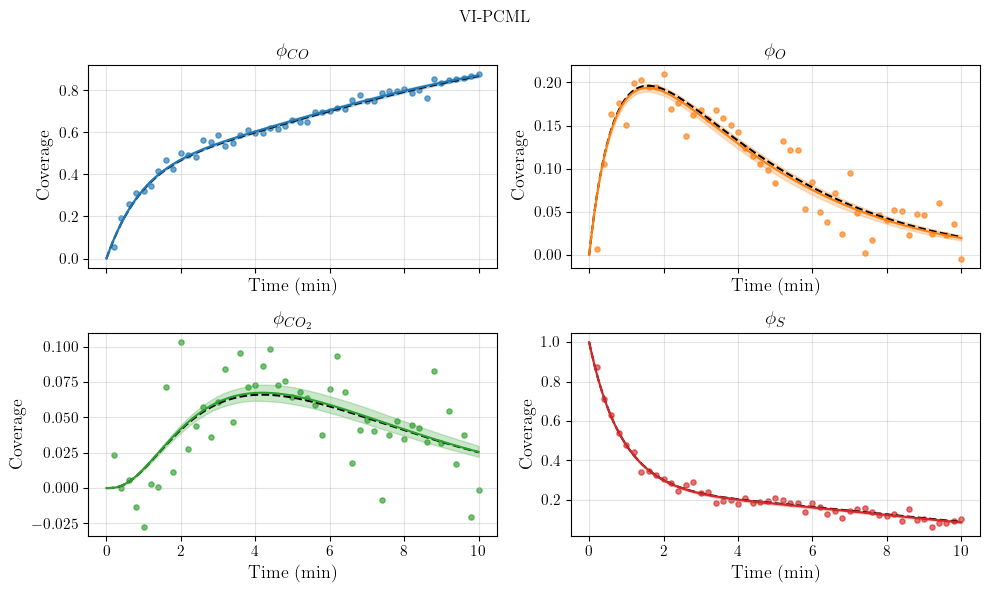

In [7]:
rng_post = np.random.default_rng(SEED+1)
k_post = np.exp(mu + sd_log*rng_post.normal(size=(500, 4)))
physical_predict_many = jit(vmap(lambda k: rk4(kinetic_rhs, x0_j, t_plot_j, k)))
vi_paths = np.asarray(physical_predict_many(jnp.array(k_post)))
if not np.isfinite(vi_paths).all() or vi_paths.min() < -1e-8:
    raise RuntimeError("Invalid physical integration; reduce DT and rerun.")
vi_mean = vi_paths.mean(axis=0)
vi_lo, vi_hi = np.quantile(vi_paths, [0.025, 0.975], axis=0)
four_species_plot(vi_mean, "VI-PCML", vi_lo, vi_hi)

### 8. Compare all four species on the same time axis
Solid lines are model predictions, dashed lines are the synthetic truth, and points are noisy measurements. All three models are trained and compared over the same 0–10 min interval.

- **Single NODE:** one point estimate of the neural vector field; no uncertainty band.
- **50-NODE ensemble:** empirical spread across independently initialized fits; not a Bayesian posterior.
- **VI-PCML:** uncertainty induced by an approximate posterior over model parameters, conditional on a specified mechanism, prior, noise model, and known initial state.

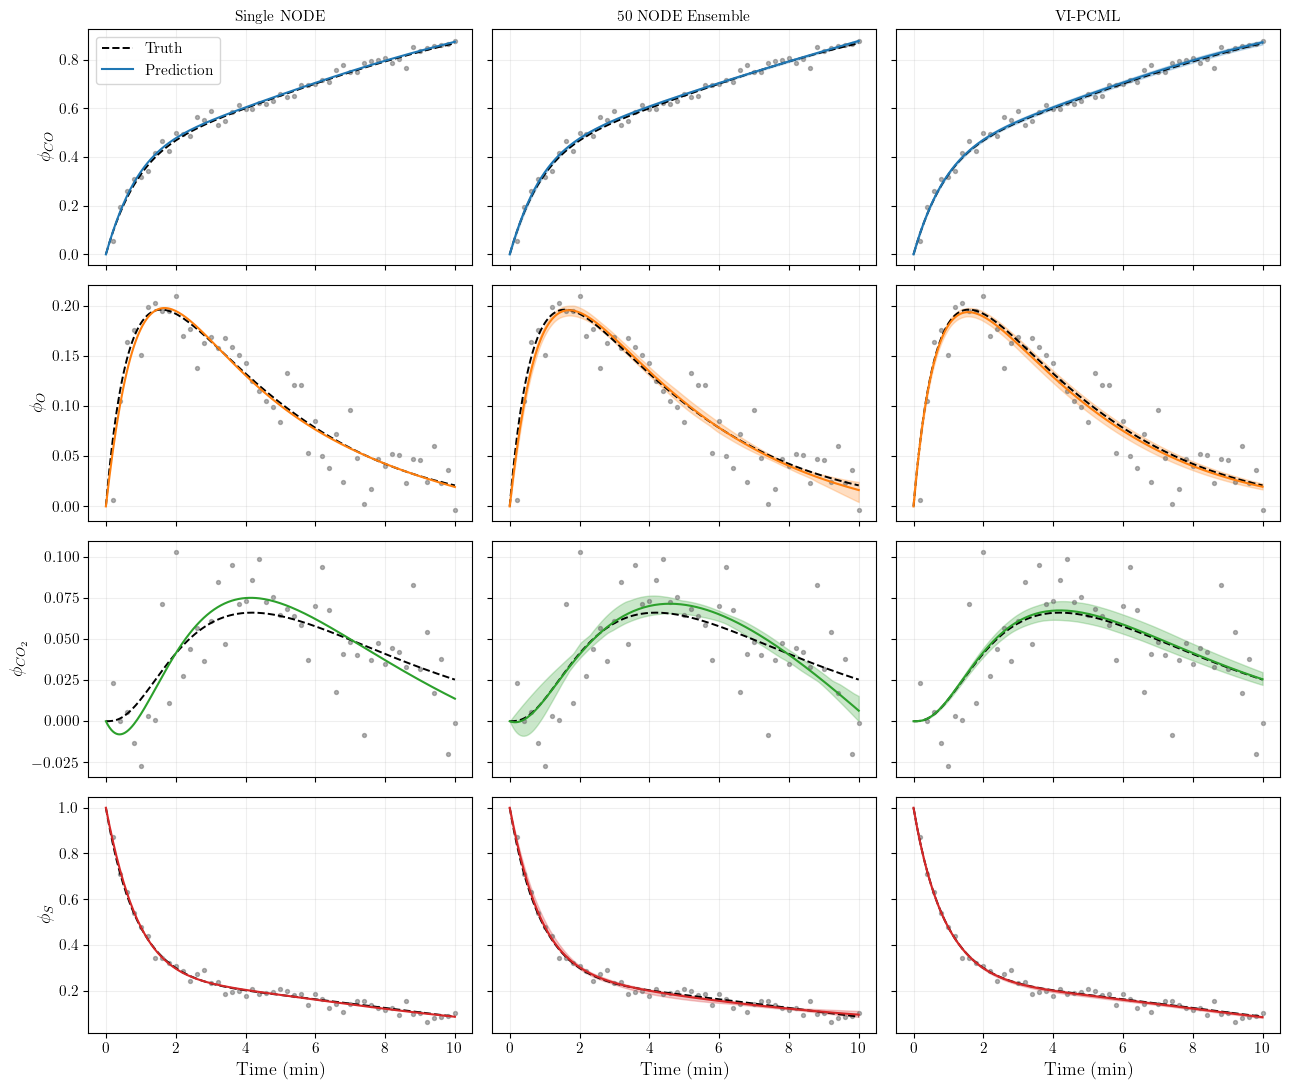

In [8]:
fig, axes = plt.subplots(4, 3, figsize=(13, 11), sharex=True, sharey="row")
comparisons = [("Single NODE", single_pred, None, None),
               ("50 NODE Ensemble", ensemble_mean, ensemble_lo, ensemble_hi),
               ("VI-PCML", vi_mean, vi_lo, vi_hi)]
for col, (name, mean, lower, upper) in enumerate(comparisons):
    for j in range(4):
        ax = axes[j, col]
        ax.plot(t_plot, y_true[:, j], "k--", lw=1.4, label="Truth")
        ax.plot(t_plot, mean[:, j], color=colors[j], label="Prediction")
        if lower is not None:
            ax.fill_between(t_plot, lower[:, j], upper[:, j], color=colors[j], alpha=0.25)
        ax.scatter(t_obs, y_obs[:, j], color="0.4", s=8, alpha=0.5)
        ax.grid(alpha=0.2)
        if j == 0: ax.set_title(name, fontsize=11)
        if col == 0: ax.set_ylabel(labels[j])
        if j == 3: ax.set_xlabel("Time (min)")
axes[0, 0].legend()
fig.tight_layout()
plt.show()

### 9. Key takeaways

- A neural ODE fits the data but provides no uncertainty; an ensemble provides a spread that only reflects initialization (Modules 1 and 3).
- Embedding the known kinetic structure (physics) and quantifying uncertainty with VI gives physically consistent predictions
  with meaningful uncertainty (Modules 2 and 3).
- VI estimates the parameters and their uncertainty simultaneously by solving an optimization problem with Adam (Module 3).
- Tools: JAX (automatic differentiation, vectorization), a fixed-step Runge-Kutta solver, and Adam (Module 4).

### 10. Optional exercises

1. **Prior strength.** Change the prior log-standard deviation `prior_sd` from 0.6 to 0.3 and to 1.0. How do the VI
   intervals of $k$ and the prediction bands change?
2. **Monte Carlo samples.** Change `MC_SAMPLES` (the number of samples $N_s$ in the ELBO) to 1 and to 128. How do the
   noise of the objective and the final estimates change?
3. **Ensemble size.** Train an ensemble of 10 instead of 50 neural ODEs. Does the spread change? Does it ever become a
   posterior?
4. **Extrapolation.** Simulate all models beyond the 10 min training window. Which models remain physically consistent?
5. **Physics.** Check that every VI sample satisfies $\phi_{CO}+\phi_O+\phi_{CO_2}+\phi_S=1$. Does the neural ODE?

### References
- Chen, R. T. Q., Rubanova, Y., Bettencourt, J., and Duvenaud, D. (2018). *Neural Ordinary Differential Equations*. NeurIPS. https://arxiv.org/abs/1806.07366
- Kingma, D. P., and Welling, M. (2014). *Auto-Encoding Variational Bayes*. ICLR. Reparameterization-based variational optimization. https://arxiv.org/abs/1312.6114
- Kingma, D. P., and Ba, J. (2015). *Adam: A Method for Stochastic Optimization*. ICLR. https://arxiv.org/abs/1412.6980
- Mukherjee, A., and Zavala, V. M. (2026). *Physics-constrained machine learning for chemical engineering*. Current Opinion in Chemical Engineering, 51, 101228. https://doi.org/10.1016/j.coche.2026.101228